# Module 4 — Change Analysis & Kepner-Tregoe "Is / Is-Not"

Part of the Root-Cause Analysis Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- Most wrong root causes *do* explain the problem. What they fail to explain is where the problem *didn't* happen.
- Kepner-Tregoe problem analysis makes that check systematic: for each dimension of the problem, write down what it **is** and what it **could be, but is not**. A cause must explain both.
- In DMAIC (Define, Measure, Analyze, Improve, Control), it bridges **Measure** (fixing the problem's exact boundary) and **Analyze** (testing causes against that boundary).

**What this module produces:**
1. An is / is-not table for a real incident, on four dimensions: what, where, when, extent.
2. Six candidate causes, each tested against the table.
3. A check that tells apart the last two survivors.

## From the curriculum

> ## <u>Module 4 — Change Analysis & Kepner-Tregoe "Is / Is-Not"</u>
>
> **DMAIC phase:** Measure into Analyze (fixing the problem's boundary, then
> asking what changed at that boundary).
>
> **Concepts**
> - Kepner-Tregoe problem analysis (from Charles Kepner and Benjamin Tregoe's
>   work on management decisions): specifying the problem on four dimensions
>   (what, where, when, extent), each as "is" vs. "could be, but is not"
> - Distinctions: what is true only on the "is" side
> - Changes: what changed in, on, or around each distinction, and when
> - Testing a possible cause: it must explain both the "is" and the "is not";
>   a cause that explains the problem but also predicts problems that never
>   happened is rejected
> - Change analysis as a stand-alone technique: comparing the problem
>   situation with a similar situation that had no problem
>
> **Why it matters**
> The "is not" column is the strongest elimination tool in RCA. It kills causes
> that explain the problem but also predict problems that never happened.
>
> **Worked example**
> The E04 activation cliff (a take-home exercise with artificial data, 24,436
> product events, 1 Dec 2025 to 25 Jan 2026), recomputed. It was a textbook
> is / is-not case, done unnamed:
> - **What:** only the `share_room` event fell (85% fewer per day); every other
>   event, room creation included, held up.
> - **Where:** every segment fell together.
> - **When:** a calendar date, 12 Jan. Even long-standing users stopped
>   sharing that day.
> - **Testing the causes:** six candidate causes are tested against the
>   is / is-not table. The original analysis left two open: the share action broke, or
>   only its tracking event broke. A check the original recommended but never
>   ran settles it: buyers kept viewing new rooms after 12 Jan at the same
>   rate, so rooms were still being shared, and only the tracking event broke.
>
> **Resources**
> - [Kepner-Tregoe Matrix](https://digital.ahrq.gov/health-it-tools-and-resources/evaluation-resources/workflow-assessment-health-it-toolkit/all-workflow-tools/kepner-tregoe-matrix)
>   (U.S. Agency for Healthcare Research and Quality, ~5 min, verified): the
>   is / is-not columns, the distinction step, and testing each cause against
>   every observation.
>
> **Exercise type:** test a teammate's proposed cause against the is / is-not
> table. Fully worked.
>
> **Interview angle:** "The metric dropped for some users but not others. How
> do you narrow it down?"

## Lesson

### The method, in five steps

1. **Specify the problem** on four dimensions. For each, fill two columns:
   - **is:** what the problem affects
   - **is not:** what it *could* plausibly affect, but does not (the closest comparison)

| dimension | the question | is | is not |
|---|---|---|---|
| **what** | which object, which defect? | | |
| **where** | where is it seen (segment, location, step)? | | |
| **when** | when did it start, any pattern? | | |
| **extent** | how many, how big, growing or not? | | |

2. **Distinctions:** what is true only of the "is" side? (e.g. "only this event", "only from this date")
3. **Changes:** what changed in, on, or around each distinction, and when?
4. **Test each possible cause:** it must explain *every* "is" and *every* "is not". A cause that predicts a problem in an "is not" cell is rejected.
5. **Verify** the surviving cause with a check that would come out differently if it were wrong.

### Why the "is not" column matters most

Many causes could produce the problem. Few could produce it *and* leave the "is not" cells untouched. The "is not" column is where causes die.

### Change analysis

A simpler cousin of the same idea: compare the problem situation with the most similar situation that had no problem (the same product before the date, the same step for another group) and list every difference. Each difference is a candidate cause. Steps 1–3 above are change analysis done dimension by dimension.

## Worked example: the E04 activation cliff

**Data choice: reuse.** E04 was an is / is-not analysis in all but name: it found that only one step broke, on one calendar date, in every segment. Re-running it with the method's structure shows the method, and lets it finish a check the original left open.

**Where this was already done, unnamed:** the user's E04 exercise (`AI Analyst Workspace/Reports/E04_Summary.md`, a local file), which ended with two candidate causes it could not tell apart.

**The data:** a take-home exercise with artificial data. One row per product event (signups, room creation, sharing, buyer page views and others), with the user's channel, plan, company size and account type on every row. A seller creates a "room" (a page for a deal) and **shares** it with a buyer; sharing is the activation event, `share_room`. Every user in this data is a seller; buyers have no user rows, and a buyer viewing a shared room is recorded as `buyer_page_view` on the **seller's** row. The source file is not redistributed here (take-home exercise data); `python data/get_data.py` copies it from the local E04 folder and checks it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import common
from common import show, BLUE, ORANGE, GREY

ev = common.load_e04()
ddmm = lambda x: pd.Timestamp(x).strftime("%d.%m")
end = ev["event_timestamp"].max()
print("What is in the data?")
print(f"  events = {len(ev):,}")
print(f"  event types = {ev['event_name'].nunique()}")
print(f"  users who signed up = {ev.loc[ev['event_name'] == 'sign_up', 'user_id'].nunique():,}")
print(f"  first event = {ev['event_timestamp'].min():%Y-%m-%d %H:%M}")
print(f"  last event = {end:%Y-%m-%d %H:%M} (the last day is cut off at noon)")
_room = ev[ev["event_name"] == "room_created"].groupby("user_id")["event_timestamp"].min()
_share = ev[ev["event_name"] == "share_room"].groupby("user_id")["event_timestamp"].min()
_gap = ((_share - _room).dropna().dt.total_seconds() / 86400)
_gap = _gap[(_gap >= 0) & (_share.reindex(_gap.index) < "2026-01-12")]
print(f"\nDays from a seller's first room to first share (sellers who shared before 12 Jan, {len(_gap)} sellers):")
print(f"  median = {_gap.median():.1f}")
print(f"  shared within 7 days = {(_gap <= 7).mean():.0%}")

What is in the data?
  events = 24,436
  event types = 12
  users who signed up = 4,072
  first event = 2025-12-01 06:00
  last event = 2026-01-25 12:00 (the last day is cut off at noon)

Days from a seller's first room to first share (sellers who shared before 12 Jan, 462 sellers):
  median = 3.5
  shared within 7 days = 90%


**Data quality first** (from the original E04 checks, which this module does not change):
- **The last day is partial:** events stop at 12:00 on 25 Jan. Daily comparisons below stop at 24 Jan.
- **Recent users have had less time to share.** Sharing comes days after a room is created (printed below), so a seller who created a room yesterday has not "failed" to share yet. To compare fairly, sharing is counted **within 7 days of the seller's first room** (7 days chosen, because 90% of first shares came within it, printed below), only for sellers with at least 7 days of data after it: first room by 18 Jan, 12:00. So the newer group below is labelled "first room 12-18 Jan".
- **The funnel has a known logging gap:** the original E04 checks reported that about 10–12% of users miss one of the signup-detail events, from before the incident. It does not involve `share_room`.

### Part 1 — What: which events fell?

The problem was first seen as "activation fell". The **what** question: is it one event, or many?

The cut-off is 12 Jan: the day the daily `share_room` count dropped (printed first below; Part 3 shows the full daily series).

In [2]:
sr = ev[ev["event_name"] == "share_room"].groupby("day").size()
print("Why 12 Jan? share_room events:")
print(f"  on 11.01 = {sr.get(pd.Timestamp('2026-01-11'), 0)}")
print(f"  on 12.01 = {sr.get(pd.Timestamp('2026-01-12'), 0)}\n")
before = ev[(ev["day"] >= "2025-12-01") & (ev["day"] <= "2026-01-11")]
after = ev[(ev["day"] >= "2026-01-12") & (ev["day"] <= "2026-01-24")]
n_before, n_after = before["day"].nunique(), after["day"].nunique()
w = pd.DataFrame({"per day, 01.12-11.01": before["event_name"].value_counts() / n_before,
                  "per day, 12.01-24.01": after["event_name"].value_counts() / n_after})
w["change"] = w.iloc[:, 1] / w.iloc[:, 0] - 1
w = w.sort_values("change")
print(f"Events per day, before vs. from 12 Jan (days before = {n_before}, days after = {n_after}):\n")
show(pd.DataFrame({"event": w.index, "per day, 01.12-11.01": w.iloc[:, 0].map("{:.2f}".format).to_numpy(),
                   "per day, 12.01-24.01": w.iloc[:, 1].map("{:.2f}".format).to_numpy(),
                   "change": w["change"].map("{:+.0%}".format).to_numpy()}))

Why 12 Jan? share_room events:
  on 11.01 = 11
  on 12.01 = 1

Events per day, before vs. from 12 Jan (days before = 42, days after = 13):

event                per day, 01.12-11.01  per day, 12.01-24.01  change
share_room                          11.00                  1.62    -85%
user_details                        65.45                 50.00    -24%
account_details                     63.88                 49.08    -23%
sign_up                             78.10                 60.92    -22%
finished_signup                     53.69                 42.54    -21%
room_created                        27.40                 25.92     -5%
comment_added                       36.52                 42.77    +17%
buyer_page_view                     30.74                 38.08    +24%
page_view                           19.98                 31.85    +59%
login                               18.86                 31.38    +66%
notification_sent                   18.62                 32.23    +

**Observation:** there were 85% fewer `share_room` events per day (11.00 to 1.62). The signup events fell by 21–24%, in line with fewer signups overall. Room creation held (−5%). Every other event *rose*, including `buyer_page_view` (+24%).

- **is:** the `share_room` event
- **is not:** room creation, the signup steps (which fell, but only as much as signups did), and every other product event

### Part 2 — Where: which users stopped sharing?

Could it be one channel, one plan, one company size? The **where** question, using the fair measure: shared within 7 days of the first room.

In [3]:
first_room = ev[ev["event_name"] == "room_created"].groupby("user_id")["event_timestamp"].min()
def first_after_room(name):
    e = ev[ev["event_name"] == name][["user_id", "event_timestamp"]].merge(first_room.rename("first_room"), left_on="user_id", right_index=True)
    return e[e["event_timestamp"] >= e["first_room"]].groupby("user_id")["event_timestamp"].min()

u = first_room.rename("first_room").to_frame()
u["shared within 7 days"] = (first_after_room("share_room").reindex(u.index) - u["first_room"]) <= pd.Timedelta(days=7)
u["buyer view within 7 days"] = (first_after_room("buyer_page_view").reindex(u.index) - u["first_room"]) <= pd.Timedelta(days=7)
u = u[u["first_room"] <= end - pd.Timedelta(days=7)]
u["period"] = np.where(u["first_room"] < "2026-01-12", "first room before 12 Jan", "first room 12-18 Jan")
attrs = ev.drop_duplicates("user_id").set_index("user_id")[["signup_channel", "plan", "company_size", "account_type"]]
u = u.join(attrs)
u["company_size"] = u["company_size"].fillna("none (private account)")

for dim, label in [("signup_channel", "signup channel"), ("plan", "plan"), ("company_size", "company size"), ("account_type", "account type")]:
    t = u.groupby([dim, "period"])["shared within 7 days"].agg(["mean", "size"]).unstack("period")
    print(f"Shared within 7 days of the first room, by {label}:\n")
    show(pd.DataFrame({label: t.index,
                       "before 12 Jan": t[("mean", "first room before 12 Jan")].map("{:.1%}".format).to_numpy(),
                       "users": t[("size", "first room before 12 Jan")].to_numpy(),
                       "12-18 Jan": t[("mean", "first room 12-18 Jan")].map("{:.1%}".format).to_numpy(),
                       "users ": t[("size", "first room 12-18 Jan")].to_numpy(),
                       "change": (t[("mean", "first room 12-18 Jan")] / t[("mean", "first room before 12 Jan")] - 1).map("{:+.0%}".format).to_numpy()}))
    print()

Shared within 7 days of the first room, by signup channel:

signup channel    before 12 Jan  users  12-18 Jan  users   change
content                   39.4%     99      18.8%      16    -52%
direct                    33.8%    145       0.0%      17   -100%
google_organic            41.8%    146      10.0%      20    -76%
google_paid               19.5%    287       3.0%      33    -84%
linkedin_organic          45.4%    304       4.1%      49    -91%
referral                  45.9%    170      10.3%      29    -77%

Shared within 7 days of the first room, by plan:

plan        before 12 Jan  users  12-18 Jan  users   change
ENTERPRISE          50.0%     16       0.0%       2   -100%
FREE                36.8%    968       7.0%     142    -81%
FREE_PLUS           34.1%    123       0.0%      17   -100%
STARTUP             34.1%     44      33.3%       3     -2%

Shared within 7 days of the first room, by company size:

company size            before 12 Jan  users  12-18 Jan  users   cha

Each segment's "12-18 Jan" group is small (15–49 sellers, fewer for some plans), so read the direction, not the exact size.

**Observation:** sharing fell in every channel (for example linkedin_organic 45.4% to 4.1%, referral 45.9% to 10.3%), every company size and both account types. Within plans, the two large ones fell (FREE 36.8% to 7.0%, FREE_PLUS 34.1% to 0.0%); STARTUP (3 users after) and ENTERPRISE (2) are too small to read.

- **is:** every segment
- **is not:** no segment was spared

A problem that is everywhere still says something: the cause must be common to every user, not specific to one group.

### Part 3 — When: a date, or an age?

"Users who joined recently share less" (an age pattern) and "everyone stopped sharing on one day" (a calendar pattern) point to different causes. The **when** question:

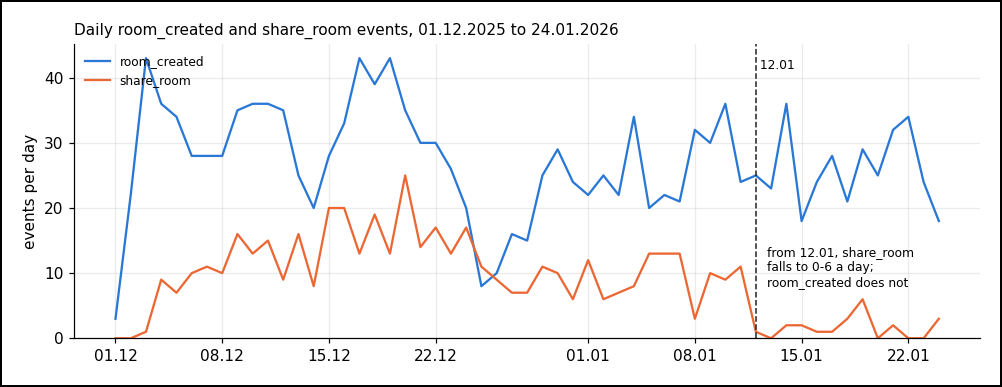

In [4]:
daily = ev[ev["day"] <= "2026-01-24"].pivot_table(index="day", columns="event_name", values="event_id", aggfunc="size").fillna(0)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(daily.index, daily["room_created"], color=BLUE, lw=1.5, label="room_created")
ax.plot(daily.index, daily["share_room"], color=ORANGE, lw=1.5, label="share_room")
ax.axvline(pd.Timestamp("2026-01-12"), color="#222222", lw=1, ls="--")
ax.text(pd.Timestamp("2026-01-12"), ax.get_ylim()[1] * 0.95, " 12.01", fontsize=8, va="top")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: pd.Timestamp(plt.matplotlib.dates.num2date(v)).strftime("%d.%m")))
ax.set_ylim(bottom=0)
ax.set_ylabel("events per day")
ax.set_title("Daily room_created and share_room events, 01.12.2025 to 24.01.2026", fontsize=10, loc="left")
ax.text(pd.Timestamp("2026-01-12 18:00"), 8, "from 12.01, share_room\nfalls to 0-6 a day;\nroom_created does not", fontsize=8)
ax.legend(fontsize=8, frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

In [5]:
s = ev[ev["event_name"] == "share_room"]
old = first_room[first_room < "2026-01-01"].index
jan1_11 = s[(s["day"] >= "2026-01-01") & (s["day"] <= "2026-01-11")]
jan12_24 = s[(s["day"] >= "2026-01-12") & (s["day"] <= "2026-01-24")]
d_after = daily.loc["2026-01-12":"2026-01-24", "share_room"]
print(f"share_room events per day, 12.01-24.01: lowest = {d_after.min():.0f}, highest = {d_after.max():.0f}\n")
print("Did long-standing sellers stop sharing too? (sellers whose first room was in December)")
print(f"  share_room events per day, 01.01-11.01 = {jan1_11['user_id'].isin(old).sum()} ÷ 11 = {jan1_11['user_id'].isin(old).sum() / 11:.2f}")
print(f"  share_room events per day, 12.01-24.01 = {jan12_24['user_id'].isin(old).sum()} ÷ 13 = {jan12_24['user_id'].isin(old).sum() / 13:.2f}")

share_room events per day, 12.01-24.01: lowest = 0, highest = 6

Did long-standing sellers stop sharing too? (sellers whose first room was in December)
  share_room events per day, 01.01-11.01 = 35 ÷ 11 = 3.18
  share_room events per day, 12.01-24.01 = 0 ÷ 13 = 0.00


**Observation:** `share_room` drops on 12 Jan and stays low (0–6 a day), while room creation carries on at its usual level.

**Observation:** sellers whose first room was in December, weeks before, shared 35 times in 1–11 Jan and **0 times** in 12–24 Jan. Their "age" did not change on 12 Jan, so this is a calendar date, not an age pattern.

- **is:** from 12 Jan, for new and old sellers alike
- **is not:** before 12 Jan; not a gradual decline by user age

### Part 4 — Extent: how big, and is it changing?

The **extent** question: how large is the drop, and does it grow, shrink or hold over the two weeks?

In [6]:
by = u.groupby("period")[["shared within 7 days", "buyer view within 7 days"]].agg(["sum", "size", "mean"])
print("How big is the drop? Shared within 7 days of the first room:")
for p in ["first room before 12 Jan", "first room 12-18 Jan"]:
    print(f"  {p} = {by.loc[p, ('shared within 7 days', 'sum')]} ÷ {by.loc[p, ('shared within 7 days', 'size')]} = {by.loc[p, ('shared within 7 days', 'mean')]:.1%}")
wk1, wk2 = daily.loc["2026-01-12":"2026-01-18", "share_room"].mean(), daily.loc["2026-01-19":"2026-01-24", "share_room"].mean()
print("\nIs it growing or shrinking? share_room events per day:")
print(f"  12.01-18.01 = {wk1:.2f}")
print(f"  19.01-24.01 = {wk2:.2f}")

How big is the drop? Shared within 7 days of the first room:
  first room before 12 Jan = 421 ÷ 1151 = 36.6%
  first room 12-18 Jan = 11 ÷ 164 = 6.7%

Is it growing or shrinking? share_room events per day:
  12.01-18.01 = 1.43
  19.01-24.01 = 1.83


**Observation:** among sellers with a fair 7-day window, sharing fell from 36.6% to 6.7%. It did not fall to zero: 11 of 164 newer sellers still shared. The low level holds across both weeks; it neither recovers nor deepens.

### Part 5 — The is / is-not table

Everything above, in one place:

| dimension | is | is not | distinction (true only of "is") |
|---|---|---|---|
| **what** | the `share_room` event: 85% fewer per day (11.00 to 1.62) | room creation (−5%), signup steps (−21% to −24%, like signups), every other event (+17% to +82%), including `buyer_page_view` (+24%) | only the sharing *event* fell |
| **where** | every channel, plan, company size and account type | no segment spared | common to all users |
| **when** | from 12 Jan, a calendar date; long-standing sellers too (35 shares in 1–11 Jan, 0 in 12–24 Jan) | before 12 Jan; not a user-age pattern | a single date |
| **extent** | shared within 7 days: 36.6% to 6.7% | not to zero (11 of 164 still shared) | large, but partial (why some still shared is left open) |

**Changes:** the data has no record of releases or settings, so the change on 12 Jan cannot be seen directly. What the distinctions say about it: one change, on one date, affecting every user, and sharing (or its record) is the only event that *fell*. Several other events rose sharply from the same date (logins +66%, integration clicks +82%); that is unexplained, and possibly part of the same change.

### Part 6 — Test each possible cause against the table

The six candidates come from the original E04 analysis. It ruled out four of them, and left the last two open. Here, each candidate must explain every "is" *and* every "is not":

| # | possible cause | explains "is"? | explains "is not"? | verdict |
|---|---|---|---|---|
| 1 | fewer signups from google_paid (signups per day fell 22% overall, Part 1) | partly: fewer signups means fewer shares in total, but not a lower sharing rate (sellers who shared within 7 days ÷ sellers with a first room) | **no:** sharing fell inside every channel, not just google_paid (where) | rejected |
| 2 | recent users have not had time to share yet | partly: it would lower sharing for the newest sellers only | **no:** the 7-day window removes this, and December sellers stopped too (when) | rejected |
| 3 | users disengaged, or the site was down | yes | **no:** every other event held or rose, including buyer page views (what) | rejected |
| 4 | a broken signup or onboarding flow | partly: it would lower sharing for new sellers only | **no:** room creation held (−5%), and old sellers who never re-onboard stopped too (what, when) | rejected |
| 5 | a change on 12 Jan broke the **share action** itself (product break) | yes | yes, as far as the table goes | survives |
| 6 | a change on 12 Jan broke only the **`share_room` tracking event**: sharing still works, it is just not recorded (tracking break) | yes | yes, as far as the table goes | survives |

**Observation:** four causes explain at least part of the drop but die on an "is not" cell. Two survive, and the original E04 analysis stopped here: it could not tell them apart.

### Part 7 — Verify: tell the two survivors apart

Step 5 of the method: find a check that comes out differently depending on which cause is true. The two survivors make different predictions about **buyers**:
- If the share action broke (cause 5), buyers stop receiving rooms, so buyer page views after a new room should fall too.
- If only the tracking event broke (cause 6), buyers still receive rooms, so buyer page views should carry on as before.

First, is a buyer page view a fair sign that a room was shared? Before 12 Jan, when both events were recorded, does a buyer view follow a share? (sellers with a fair 7-day window)

In [7]:
pre = u[u["period"] == "first room before 12 Jan"]
sh_t = first_after_room("share_room").reindex(pre.index)
bv_t = first_after_room("buyer_page_view").reindex(pre.index)
both = pre["shared within 7 days"] & pre["buyer view within 7 days"]
first_ok = (sh_t[both] <= bv_t[both]).sum()
n_bv = pre["buyer view within 7 days"].sum()
n_bv_noshare = (pre["buyer view within 7 days"] & ~pre["shared within 7 days"]).sum()
n_sh = pre["shared within 7 days"].sum()
share_to_view = both.sum() / n_sh
print(f"  sellers with both a share and a buyer view = {both.sum()}")
print(f"  of those, the share came first = {first_ok} of {both.sum()} = {first_ok / both.sum():.1%}")
print()
print(f"  sellers with a buyer view = {n_bv}")
print(f"  of those, with no recorded share = {n_bv_noshare} of {n_bv} = {n_bv_noshare / n_bv:.1%}")
print()
print(f"  sellers with a share = {n_sh}")
print(f"  of those, also had a buyer view = {both.sum()} of {n_sh} = {share_to_view:.1%}")

  sellers with both a share and a buyer view = 299
  of those, the share came first = 299 of 299 = 100.0%

  sellers with a buyer view = 321
  of those, with no recorded share = 22 of 321 = 6.9%

  sellers with a share = 421
  of those, also had a buyer view = 299 of 421 = 71.0%


**Observation:** before 12 Jan, a seller's first buyer view came after their first share in all 299 cases with both, and only 22 of the 321 sellers with a buyer view (6.9%) had no recorded share. So a buyer view is a good sign that a room had been shared. Now the test.

Within 7 days of the first room:

In [8]:
show(pd.DataFrame({
    "measure": ["shared (share_room event)", "buyer viewed the room (buyer_page_view event)"],
    "first room before 12 Jan": [f"{by.loc['first room before 12 Jan', (c, 'sum')]} ÷ {by.loc['first room before 12 Jan', (c, 'size')]} = {by.loc['first room before 12 Jan', (c, 'mean')]:.1%}"
                                 for c in ["shared within 7 days", "buyer view within 7 days"]],
    "first room 12-18 Jan": [f"{by.loc['first room 12-18 Jan', (c, 'sum')]} ÷ {by.loc['first room 12-18 Jan', (c, 'size')]} = {by.loc['first room 12-18 Jan', (c, 'mean')]:.1%}"
                               for c in ["shared within 7 days", "buyer view within 7 days"]],
}))
post = u[u["period"] == "first room 12-18 Jan"]
nb2 = post["buyer view within 7 days"].sum(); nb2n = (post["buyer view within 7 days"] & ~post["shared within 7 days"]).sum()
print(f"\nFirst room 12-18 Jan: sellers with a buyer view but no recorded share = {nb2n} of {nb2} = {nb2n / nb2:.1%} (before 12 Jan: 6.9%)")

measure                                        first room before 12 Jan  first room 12-18 Jan
shared (share_room event)                      421 ÷ 1151 = 36.6%        11 ÷ 164 = 6.7%
buyer viewed the room (buyer_page_view event)  321 ÷ 1151 = 27.9%        47 ÷ 164 = 28.7%

First room 12-18 Jan: sellers with a buyer view but no recorded share = 40 of 47 = 85.1% (before 12 Jan: 6.9%)


How many first room 12-18 Jan sellers really shared? (estimate, assuming 71.0% of sharers still get a buyer view, as before 12 Jan)

In [9]:
n_post = len(post)
est = nb2 / share_to_view
print(f"  sellers with a buyer view = {nb2} of {n_post}")
print(f"  sellers who shared ≈ {nb2} ÷ {share_to_view:.1%} = {est:.0f} of {n_post} = {est / n_post:.1%}")
print(f"  recorded as shared = {post['shared within 7 days'].sum()} of {n_post} = {post['shared within 7 days'].mean():.1%}")
print(f"  before 12 Jan, recorded as shared = {n_sh} of {len(pre)} = {n_sh / len(pre):.1%}")

  sellers with a buyer view = 47 of 164
  sellers who shared ≈ 47 ÷ 71.0% = 66 of 164 = 40.4%
  recorded as shared = 11 of 164 = 6.7%
  before 12 Jan, recorded as shared = 421 of 1151 = 36.6%


**Observation:** recorded sharing fell from 36.6% to 6.7%, but buyers viewed new rooms at the same rate as before (27.9% to 28.7%). Of the sellers whose first room was 12–18 Jan, 40 of the 47 with a buyer view (85.1%) had no recorded share, against 6.9% before. These are sellers whose *first* room was from 12 Jan, so the buyers were viewing those new rooms, not older ones.

**Conclusion (from this data):** buyers kept receiving rooms, so rooms were still being shared. The share action worked; what stopped on 12 Jan was the **`share_room` event that records it**. Cause 6 survives; cause 5 is rejected by a new "is not": buyer page views did not fall.

**What would confirm it in a real company:** the release or settings change from 12 Jan that touched the share event, and the share feature's own server-side records for those days. With a `room_id` on `room_created`, `share_room` and `buyer_page_view` (as the user's own E04 event design proposed for `room_created`), the same check could be run room by room, not just seller by seller.

**Caveats:** this rests on 164 sellers (47 with a buyer view) whose first room was 12–18 Jan, and the data is artificial. It is an inference: another way of sharing that also produces buyer views, but not the `share_room` event, cannot be ruled out from this data.

**What it changes, if confirmed:** activation did not really collapse, the dashboard did. The fix is to repair the tracking event, not to redesign sharing. The missing days can be backfilled only if the share feature keeps its own server-side records.

## Exercise — A teammate's theory

A teammate says: *"On 12 Jan we must have put sharing behind a paywall for FREE-plan users. That's why activation dropped."*

Test it against the is / is-not table: what would this cause predict, and does the data agree?

In [10]:
t = u.groupby(["plan", "period"])["shared within 7 days"].agg(["mean", "size"]).unstack("period")
print("Shared within 7 days of the first room, by plan:")
for plan in ["FREE", "FREE_PLUS"]:
    print(f"  {plan}: before 12 Jan = {t.loc[plan, ('mean', 'first room before 12 Jan')]:.1%} of {t.loc[plan, ('size', 'first room before 12 Jan')]}, "
          f"12-18 Jan = {t.loc[plan, ('mean', 'first room 12-18 Jan')]:.1%} of {t.loc[plan, ('size', 'first room 12-18 Jan')]}")
print(f"Buyer viewed the room within 7 days: before 12 Jan = {by.loc['first room before 12 Jan', ('buyer view within 7 days', 'mean')]:.1%}, "
      f"12-18 Jan = {by.loc['first room 12-18 Jan', ('buyer view within 7 days', 'mean')]:.1%}")

Shared within 7 days of the first room, by plan:
  FREE: before 12 Jan = 36.8% of 968, 12-18 Jan = 7.0% of 142
  FREE_PLUS: before 12 Jan = 34.1% of 123, 12-18 Jan = 0.0% of 17
Buyer viewed the room within 7 days: before 12 Jan = 27.9%, 12-18 Jan = 28.7%


**Answer:** the theory fails on two "is not" cells.

1. **What:** a paywall stops the sharing itself, so buyers would stop seeing rooms. But buyer views held (27.9% to 28.7%). This is the stronger test.
2. **Where:** a paywall for FREE users predicts that other plans keep sharing. But FREE_PLUS users stopped too (34.1% to 0.0%), though only 17 of them had a fair window after 12 Jan, so this check is weaker.

The theory explains the "is" (FREE users shared less) but not the "is not". That is exactly the kind of cause the method is built to reject.

## Key takeaways

- **Specify the problem on four dimensions, each as "is" and "is not".** Here: what (only `share_room`, 85% fewer per day), where (every segment), when (12 Jan, even for December sellers: 35 shares to 0), extent (36.6% to 6.7%).
- **The "is not" column is where causes die.** Four of six candidate causes explained at least part of the drop but failed an "is not" cell.
- **A problem that is everywhere still narrows the search:** the cause must be common to all users, and here, tied to one date.
- **When two causes survive, design a check that separates them.** Buyer page views held (27.9% to 28.7%) while recorded sharing fell, so the tracking event most likely broke, not the sharing.
- **Change analysis is the same idea, simpler:** compare the problem situation with the closest one that had no problem, and list the differences.
- **In DMAIC, this bridges Measure and Analyze:** it fixes the problem's boundary, then tests causes against it.